Yuliia Chernysheva  
November 28, 2026  
CSC 2267: KPI Case Study

# Strategic KPI Dashboard: Apple Inc. vs. Alphabet & Meta (2019–2021)

**Business Context & Role:**  

Prepared from the perspective of the Chief Information Officer (CIO) of Apple, Inc., this strategic dashboard evaluates Apple's financial performance over a three-year period (2019–2021) and benchmarks it against two primary competitors: Alphabet, Inc. (Google) and Meta Platforms, Inc. (Facebook). The objective is to transform 36 core financial data points into actionable efficiency and market-share insights to support executive strategic decision-making.

**Data Source Attribution:**  

All underlying financial figures (Profit/Net Income, Sales/Revenue, Total Assets, and Owners' Equity in millions of USD) are publicly available domain data extracted from the U.S. Securities and Exchange Commission (SEC) EDGAR database via corporate Form 10-K annual reports (six Form 10-K filings total, two per company, accessed June 2022).

# Obtain and Inspect the Data

## Import Libraries and Color Consts

In [1]:
# Import required libraries for data manipulations & visualizations
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# Define brand color constants for consistent styling across tables and charts
COLOR_APPLE = '#00B050'    # Green
COLOR_ALPHA = '#2F75B5'    # Blue
COLOR_META  = '#C55A11'    # Brown

COMPANY_PALETTE = {
    'Apple': COLOR_APPLE,
    'Alpha': COLOR_ALPHA,   
    'Meta': COLOR_META   
}

## Load and Review Data

We use `Dataset KPI Long.csv` because its normalized structure (`Who`, `What`, `Year`, `Data`) allows vectorized group calculations in Pandas without hardcoding cell coordinates. The dataset contains 36 baseline observations (3 companies × 3 years × 4 financial attributes) with no missing values.

In [3]:
# Load the long-format dataset (36 data points: 3 companies x 3 years x 4 attributes)
kpi_long = pd.read_csv("Dataset KPI Long.csv")

# Inspect dataset structure and data types
print("=> Dataset in long format:")
display(kpi_long)

kpi_long.info()

=> Dataset in long format:


,Who,What,Year,Data
0,Apple,Profit,2019,55256
1,Apple,Sales,2019,260174
2,Apple,Assets,2019,338516
3,Apple,Equity,2019,90488
4,Alpha,Profit,2019,34343
5,Alpha,Sales,2019,161857
6,Alpha,Assets,2019,275909
7,Alpha,Equity,2019,201442
8,Meta,Profit,2019,18485
9,Meta,Sales,2019,70697


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36 entries, 0 to 35
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Who     36 non-null     object
 1   What    36 non-null     object
 2   Year    36 non-null     int64 
 3   Data    36 non-null     int64 
dtypes: int64(2), object(2)
memory usage: 1.3+ KB


## Calculate Efficiency & Growth KPIs

To prepare the dataset for executive reporting, we compute two sets of strategic indicators from the 36 baseline observations and combine them into a single enriched table:

* **Efficiency Ratios (`Return on`):** Return on Sales (ROS), Return on Assets (ROA), and Return on Equity (ROE), calculated as `(Profit / Attribute) * 100` for 2019–2021.
  
* **Three-Year Growth (2019 to 2021):** Absolute **Dollar Growth** (`2021 - 2019`), relative **Percent Growth** (`(2021 - 2019) / 2019 * 100`), and **Return Growth** in percentage points (`2021 Return % - 2019 Return %`).

In [4]:
# Calculate Efficiency KPIs: Return on Sales, Assets, and Equity (%)
profit = kpi_long.query("What == 'Profit'").set_index(['Year','Who'])["Data"]

# Compute efficiency ratios: (Profit / Attribute) * 100, rounded to whole percentages
ron_df = (
    pd.DataFrame(
        (profit / kpi_long.query("What != 'Profit'").set_index(['Year', 'Who', 'What'])['Data']) * 100
    )
    .round(0)
    .astype(int)
    .reset_index()
)
ron_df["Metric"] = "Return on"

# Calculate Growth Metrics from 2019 to 2021 (Dollars, Percent, and Return Percentage Points)
kpi2021 = kpi_long.query('Year == 2021').set_index(['Who', 'What'])['Data'] 
kpi2019 = kpi_long.query('Year == 2019').set_index(['Who', 'What'])['Data'] 

# Calculate absolute dollar growth (2019 to 2021)
dollar_growth = (kpi2021-kpi2019).reset_index()
dollar_growth["Metric"] = "Dollar Growth"
dollar_growth["Year"] = 2021

# Calculate relative percentage growth (2019 to 2021)
percent_growth = ((kpi2021-kpi2019) / kpi2019 * 100).round(0).astype(int).reset_index()
percent_growth["Metric"] = "Percent Growth"
percent_growth["Year"] = 2021

# Calculate efficiency return growth in percentage points (2021 Return % - 2019 Return %)
return_2021 = ron_df.query('Year == 2021').set_index(['Who', 'What'])['Data'] 
return_2019 = ron_df.query('Year == 2019').set_index(['Who', 'What'])['Data'] 

return_growth = (return_2021-return_2019).reset_index()
return_growth["Metric"] = "Return Growth"
return_growth["Year"] = 2021

# Combine baseline dollars with all calculated KPIs and enforce business ordering
kpi_enriched = kpi_long.assign(Metric='Dollars')

kpi_enriched = pd.concat([kpi_enriched,ron_df,dollar_growth,percent_growth,return_growth], 
                         ignore_index=True
                        )
# Enforce logical business ordering for companies and financial attributes
who_order = ['Apple', 'Alpha', 'Meta']
what_order = ['Profit', 'Sales', 'Assets', 'Equity']

kpi_enriched['Who'] = pd.Categorical(
    kpi_enriched['Who'],
    categories=who_order,
    ordered=True
)

kpi_enriched['What'] = pd.Categorical(
    kpi_enriched['What'], 
    categories=what_order, 
    ordered=True
)

kpi_enriched.head(10)

,Who,What,Year,Data,Metric
0,Apple,Profit,2019,55256,Dollars
1,Apple,Sales,2019,260174,Dollars
2,Apple,Assets,2019,338516,Dollars
3,Apple,Equity,2019,90488,Dollars
4,Alpha,Profit,2019,34343,Dollars
5,Alpha,Sales,2019,161857,Dollars
6,Alpha,Assets,2019,275909,Dollars
7,Alpha,Equity,2019,201442,Dollars
8,Meta,Profit,2019,18485,Dollars
9,Meta,Sales,2019,70697,Dollars


## Pivot KPI table

All calculated metrics are combined and reshaped into the executive summary table below. Return ratio cells for `Profit` are intentionally left blank, as return ratios are only defined for Sales, Assets, and Equity.

In [5]:
# Pivot into wide format and flatten MultiIndex columns for clean PDF export
kpi_enriched_wide = (
    kpi_enriched.pivot(index=['Who','What'], columns=['Metric','Year'],values='Data')
)
kpi_enriched_wide.columns = [f"{metric}_{year}" for metric, year in kpi_enriched_wide.columns]

# Helper to format valid integers with commas while keeping N/A cells blank
fmt_int = lambda s: s.map(lambda x: f"{int(x):,}" if pd.notna(x) else "")
fmt_pct = lambda s: s.map(lambda x: f"{int(x):,}%" if pd.notna(x) else "")

# Display cleanly formatted DataFrame (PDF-export safe)
display(kpi_enriched_wide.assign(
    Dollars_2019=lambda df: fmt_int(df['Dollars_2019']),
    Dollars_2020=lambda df: fmt_int(df['Dollars_2020']),
    Dollars_2021=lambda df: fmt_int(df['Dollars_2021']),
    Return_2019=lambda df: fmt_pct(df['Return on_2019']),
    Return_2020=lambda df: fmt_pct(df['Return on_2020']),
    Return_2021=lambda df: fmt_pct(df['Return on_2021']),
    Dollar_Growth=lambda df: fmt_int(df['Dollar Growth_2021']),
    Percent_Growth=lambda df: fmt_pct(df['Percent Growth_2021']),
    Return_Growth=lambda df: fmt_int(df['Return Growth_2021'])
)[['Dollars_2019', 'Dollars_2020', 'Dollars_2021',
   'Return_2019', 'Return_2020', 'Return_2021',
   'Dollar_Growth', 'Percent_Growth', 'Return_Growth']])

Dollars_2019 Dollars_2020 Dollars_2021 Return_2019 Return_2020  \
Who   What                                                                    
Apple Profit       55,256       57,411       94,680                           
      Sales       260,174      274,515      365,817         21%         21%   
      Assets      338,516      323,888      351,002         16%         18%   
      Equity       90,488       65,339       63,090         61%         88%   
Alpha Profit       34,343       40,269       76,033                           
      Sales       161,857      182,527      257,637         21%         22%   
      Assets      275,909      319,616      359,268         12%         13%   
      Equity      201,442      222,544      251,635         17%         18%   
Meta  Profit       18,485       29,146       39,370                           
      Sales        70,697       85,965      117,929         26%         34%   
      Assets      133,376      159,316      165,987         14%         18%   
      Equity      101,054      128,290      124,879         18%         23%   

             Return_2021 Dollar_Growth Percent_Growth Return_Growth  
Who   What                                                           
Apple Profit                    39,424            71%                
      Sales          26%       105,643            41%             5  
      Assets         27%        12,486             4%            11  
      Equity        150%       -27,398           -30%            89  
Alpha Profit                    41,690           121%                
      Sales          30%        95,780            59%             9  
      Assets         21%        83,359            30%             9  
      Equity         30%        50,193            25%            13  
Meta  Profit                    20,885           113%                
      Sales          33%        47,232            67%             7  
      Assets         24%        32,611            24%            10  
      Equity         32%        23,825            24%            14

# Strategic Visualizations

## Profit and Efficiency KPI Trends (2019–2021)

The line charts below compare Apple's solid `green` trend lines against Alphabet (`blue dashed`) and Meta (`brown dashed`) across total profit and the three efficiency ratios.

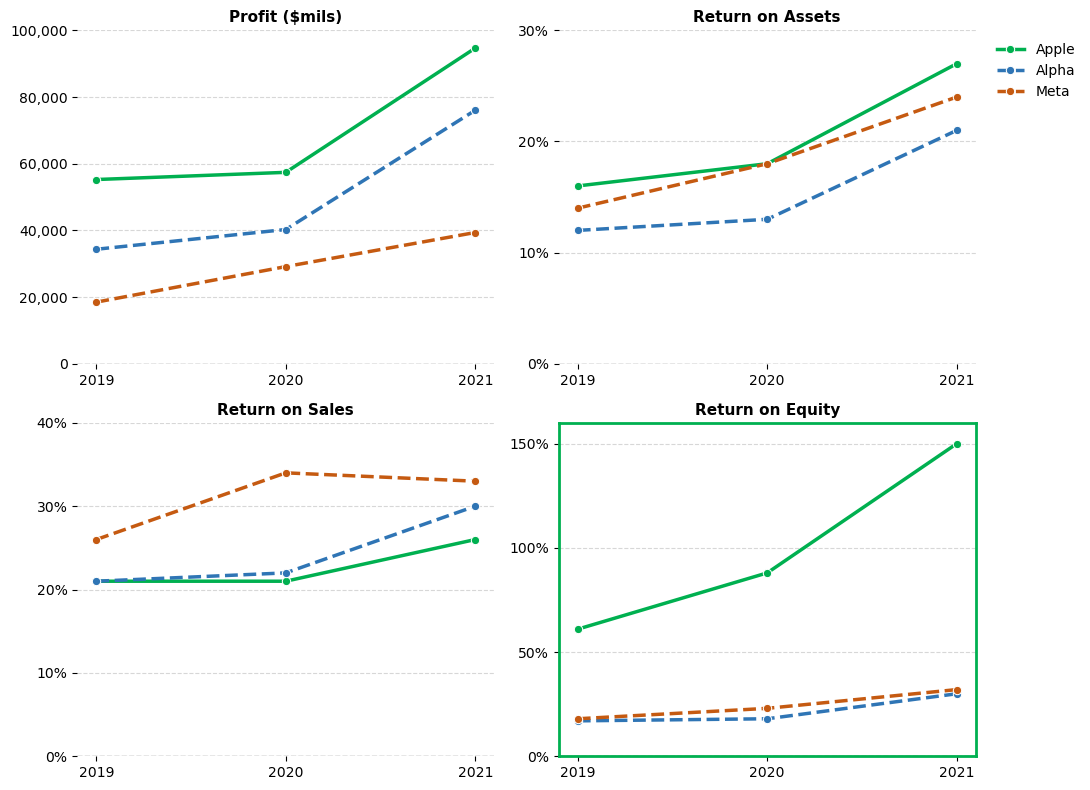

In [6]:
# Create a 2x2 grid for Profit and Efficiency KPI trends (2019–2021)
fig, axes = plt.subplots(2, 2, figsize=(11, 8))

# Tuple format: (ax, what_metric, metric_type, title, y_min, y_max, y_step, is_percent)
line_configs = [
    (axes[0, 0], 'Profit', 'Dollars',   'Profit ($mils)',    0, 100000, 20000, False),
    (axes[0, 1], 'Assets', 'Return on', 'Return on Assets',  0, 30,     10,    True),
    (axes[1, 0], 'Sales',  'Return on', 'Return on Sales',   0, 40,     10,    True),
    (axes[1, 1], 'Equity', 'Return on', 'Return on Equity',  0, 160,    50,    True),
]

for ax, what_metric, metric_type, title, y_min, y_max, y_step, is_percent in line_configs:
    subset = kpi_enriched.query("What == @what_metric & Metric == @metric_type")
    
    sns.lineplot(
        data=subset,
        x='Year',
        y='Data',
        hue='Who',
        palette=COMPANY_PALETTE,
        linewidth=2.5,
        marker='o',
        ax=ax,
        legend=False  # Disable individual subplot legends
    )
    
    # Use dashed lines for competitors to visually emphasize Apple's solid trend line
    for line in ax.get_lines():
        if line.get_color() in [COLOR_ALPHA, COLOR_META]:
            line.set_linestyle('--')
            
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.set_ylim(y_min, y_max)
    ax.set_yticks(range(y_min, y_max + 1, y_step))
    ax.set_xticks(sorted(subset['Year'].unique()))
    
    if is_percent:
        ax.yaxis.set_major_formatter('{x:.0f}%')
    else:
        ax.yaxis.set_major_formatter('{x:,.0f}')
        
    sns.despine(ax=ax, top=True, right=True, left=True, bottom=True)
    ax.grid(True, axis='y', which='major', linestyle='--', alpha=0.5)
    ax.axhline(0, color='gray', linestyle='--', linewidth=1, alpha=0.9, zorder=0)

for spine in axes[1,1].spines.values():
    spine.set_visible(True)
    spine.set_color(COLOR_APPLE)
    spine.set_linewidth(2)
    
# Add a single shared legend to the top-right subplot
axes[0, 1].legend(
    handles=axes[0, 1].get_lines()[:3],
    labels=['Apple', 'Alpha', 'Meta'],
    loc='upper left',
    bbox_to_anchor=(1.02, 1),
    frameon=False,
    fontsize=10
)

plt.tight_layout()
plt.show()

## Sales and Profit Market Share Comparison (2019 vs. 2021)

To evaluate size metrics, the pie charts below illustrate each competitor's share of combined three-company sales and profits in 2019 versus 2021, with Apple's segment exploded for visual emphasis.

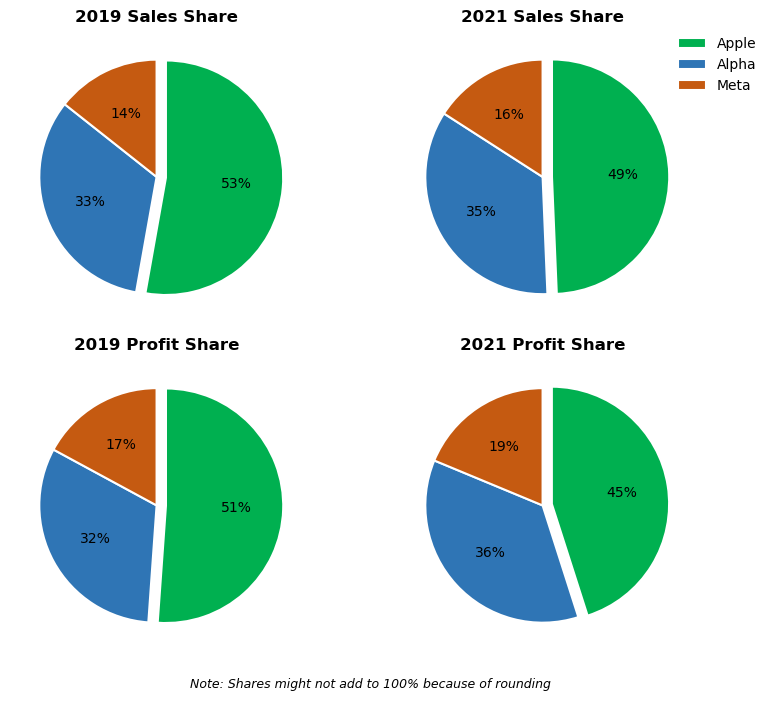

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(9, 7))

pie_configs = [
    (axes[0, 0], 'Sales',  2019, '2019 Sales Share'),
    (axes[0, 1], 'Sales',  2021, '2021 Sales Share'),
    (axes[1, 0], 'Profit', 2019, '2019 Profit Share'),
    (axes[1, 1], 'Profit', 2021, '2021 Profit Share'),
]

for ax, what_metric, year, title in pie_configs:
    subset = (kpi_enriched
        .query("What == @what_metric & Year == @year & Metric == 'Dollars'")
        .sort_values('Who'))
    
    ax.pie(
        subset['Data'],
        explode=[0.08, 0 , 0],
        colors=[COMPANY_PALETTE[c] for c in subset['Who']],
        autopct='%1.0f%%',
        startangle=90,
        counterclock=False,
        wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
    )
    ax.set_title(title, fontweight='bold')

fig.text(
    0.5, 0.01,
    "Note: Shares might not add to 100% because of rounding",
    ha='center', fontsize=9, fontstyle='italic'
)

# Add one legend to the top-right subplot
axes[0, 1].legend(['Apple', 'Alpha', 'Meta'], 
                  loc='upper left', 
                  bbox_to_anchor=(0.92, 1.02),
                  frameon=False)

plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

# Conclusions

**Profit & Efficiency Metrics:**
Compared to its competition (Alphabet and Meta), Apple has more profit, lower (but growing) return on sales, higher (and growing) return on assets, and most importantly, substantially higher (and rapidly growing) return on equity. 

Apple is a money machine. It is not quite as efficient in converting sales into profits as Alphabet and Meta, but it dominates in converting assets and especially equity into profit. Its return on equity more than doubled from 2019 to 2021 (61% growing to an unbelievable 150%, vs. only 30% and 32% for Alphabet and Meta respectively).

**Market Share Metrics (Sales & Profit):**
Apple lost sales and profit market share because Alphabet and Meta grew faster. Specifically, Apple's share of combined sales shifted from 53% in 2019 to 49% in 2021, while its share of combined profit moved from 51% to 45% over the same period, as Alphabet (+121% profit growth) and Meta (+113% profit growth) expanded at a faster percentage rate than Apple (+71% profit growth).